In [29]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score


In [30]:
df = pd.read_csv('../data/model_data_revised.csv')

In [31]:
df.columns

Index(['tmdb_id', 'imdb_id', 'title_tmdb', 'release_date', 'runtime',
       'release_year', 'n_genres', 'imdb_director_count',
       'dir_prior_success_rate_smoothed', 'dir_prior_films_log1p',
       'dir_years_active_log1p', 'dir_prior_known_films_log1p',
       'lead_actor_films_5yr_backfilled_log1p', 'company_films_5yr_log1p',
       'franchise_prior_films_log1p', 'us_certification', 'release_month',
       'is_sequel', 'is_english', 'dir_first_film', 'dir_no_track_record',
       'backfill_unavailable', 'genre_drama', 'genre_comedy', 'genre_thriller',
       'genre_action', 'genre_adventure', 'genre_crime', 'genre_romance',
       'genre_horror', 'genre_science_fiction', 'genre_family',
       'genre_fantasy', 'genre_mystery', 'genre_animation', 'genre_history',
       'genre_war', 'genre_music', 'genre_western', 'genre_documentary',
       'success'],
      dtype='object')

### Predicting if the movie was a success

In [32]:
#these identifiers need to ne kept out as they cause a data leak / high cardinality
X = df.drop(columns = ['success', 'title_tmdb','tmdb_id', 'imdb_id', 'release_date'])

#needed for the ratings
X = pd.get_dummies(X, columns=['us_certification'], dtype=int)
y = df['success']

#splitting the data for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42,    
    stratify=y          
)

#automatically fitting scaler on training set
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")


Training features shape: (5535, 41)
Testing features shape: (1384, 41)


In [33]:
print(X.columns.tolist())

['runtime', 'release_year', 'n_genres', 'imdb_director_count', 'dir_prior_success_rate_smoothed', 'dir_prior_films_log1p', 'dir_years_active_log1p', 'dir_prior_known_films_log1p', 'lead_actor_films_5yr_backfilled_log1p', 'company_films_5yr_log1p', 'franchise_prior_films_log1p', 'release_month', 'is_sequel', 'is_english', 'dir_first_film', 'dir_no_track_record', 'backfill_unavailable', 'genre_drama', 'genre_comedy', 'genre_thriller', 'genre_action', 'genre_adventure', 'genre_crime', 'genre_romance', 'genre_horror', 'genre_science_fiction', 'genre_family', 'genre_fantasy', 'genre_mystery', 'genre_animation', 'genre_history', 'genre_war', 'genre_music', 'genre_western', 'genre_documentary', 'us_certification_G', 'us_certification_NR', 'us_certification_PG', 'us_certification_PG-13', 'us_certification_R/NC-17', 'us_certification_Unknown']


In [34]:
import numpy as np

#finding where there are missing values
X_test.isna().sum()[X_test.isna().sum() > 0]

runtime    3
dtype: int64

In [35]:
df.loc[df['runtime'].isna(), ['title_tmdb', 'runtime']]

,title_tmdb,runtime
2320,Alesha Popovich and Tugarin the Dragon,NaN
2589,Dobrinya and the Dragon,NaN
3298,A.R.O.G,NaN


In [36]:
#filling in the missing values for run time with the median of the training set
runtime_median = X_train['runtime'].median()

X_train['runtime'] = X_train['runtime'].fillna(runtime_median)
X_test['runtime'] = X_test['runtime'].fillna(runtime_median)

In [37]:
X_test['runtime'].isna().sum()

0

In [38]:
#automatically fitting scaler on training set
model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter = 1000, random_state = 42,  multi_class='multinomial'))
])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1237: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, binary problems will be fit as proper binary  logistic regression models (as if multi_class='ovr' were set). Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy: 0.6763005780346821
Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.88      0.78       883
           1       0.60      0.32      0.41       501

    accuracy                           0.68      1384
   macro avg       0.65      0.60      0.60      1384
weighted avg       0.66      0.68      0.65      1384



### In-depth Metrics

In [39]:
from sklearn.metrics import classification_report
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.69      0.88      0.78       883
           1       0.60      0.32      0.41       501

    accuracy                           0.68      1384
   macro avg       0.65      0.60      0.60      1384
weighted avg       0.66      0.68      0.65      1384



### This model is doing better at predicting unsuccessful movies than it is at predicting successful movies. Both recall and precision have a higher score for 0 than for 1

precision
0: 0.69
1: 0.60

recall
0: 0.88
1: 0.32

### model is missing 68% of movies that belong in the successful category

f1-score
0: 0.78
1: 0.41

Support
0: 883
1: 501

### Confusion Matrix:

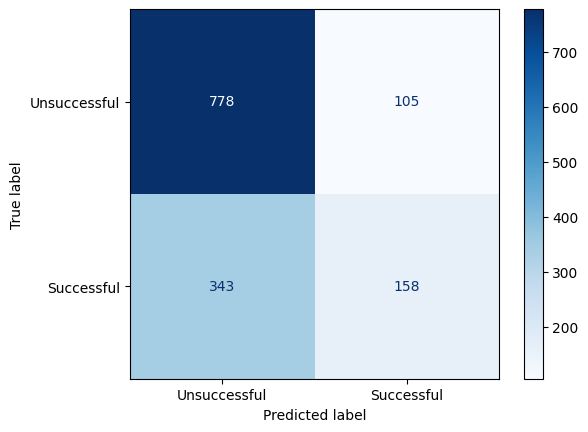

In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Unsuccessful', 'Successful']
)

disp.plot(cmap='Blues')
plt.show()

In [41]:
### rows represent actual movie outcomes and columns are the models prediction
TN= 778 #true negatives
FP= 105 #false positives
FN= 343 #false negatives
TP= 158 #true positives

### looking at the high number of false negatives as the goal for our project is to predict the success of a movie

unsuccessfullyidentified = round((TP/(TP+FN)) * 100, 2)

successfullyidentified = round((TN/(TN+FP)) * 100, 2)

print(f"The percent of unsuccesful movies identified is {unsuccessfullyidentified}")
print(f"The percent of successful movies identified is {successfullyidentified}")


The percent of unsuccesful movies identified is 31.54
The percent of successful movies identified is 88.11


### because the recall is high I am going to look at outcomes for lowered thresholds

In [42]:
from sklearn.metrics import precision_score, recall_score

y_prob = model.predict_proba(X_test)[:, 1]

thresholds = [0.5, 0.4, 0.3, 0.2]

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)

    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print()

Threshold: 0.5
Precision: 0.60
Recall: 0.32

Threshold: 0.4
Precision: 0.52
Recall: 0.51

Threshold: 0.3
Precision: 0.45
Recall: 0.76

Threshold: 0.2
Precision: 0.39
Recall: 0.93



### threshold at 0.2 had the highest recall with precision at 0.39. Precision decreased from 0.60. Based off of this I will focus on 0.30 as a threshold 

In [43]:
for threshold in [0.5, 0.3]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print(confusion_matrix(y_test, y_pred_threshold))


Threshold: 0.5
[[778 105]
 [343 158]]

Threshold: 0.3
[[413 470]
 [119 382]]


### Using F1- Score to find harmony

In [44]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.5, 0.4, 0.3, 0.2]

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1-score: {f1:.2f}")
    print()

Threshold: 0.5
Precision: 0.60
Recall: 0.32
F1-score: 0.41

Threshold: 0.4
Precision: 0.52
Recall: 0.51
F1-score: 0.51

Threshold: 0.3
Precision: 0.45
Recall: 0.76
F1-score: 0.56

Threshold: 0.2
Precision: 0.39
Recall: 0.93
F1-score: 0.55



### looking at coefficients from the model

In [46]:
model

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(max_iter=1000, multi_class='multinomial',
                                    random_state=42))])

In [54]:
coefficients = model.named_steps['model'].coef_[0]

coefficients_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': coefficients
})

coefficients_df

,Feature,Coefficient
0,runtime,0.183189
1,release_year,-0.029177
2,n_genres,-0.049114
3,imdb_director_count,0.009582
4,dir_prior_success_rate_smoothed,0.099373
5,dir_prior_films_log1p,-0.047545
6,dir_years_active_log1p,-0.139332
7,dir_prior_known_films_log1p,0.089743
8,lead_actor_films_5yr_backfilled_log1p,-0.074978
9,company_films_5yr_log1p,0.003238


### runtime, franchise_prior_films_log1-, dir_prior_success_rate_smoothed, genre_animation, and us_certification_PG-13 have a strong assocciation of success with this model

###  strongest negative coefficients were dir_years_active_log1p, is_english, and lead_actor_films_5yr_backfilled_log1p

### release_month, genre_comedy, imdb_director_count, genre_thriller, and company_films_5yr_log1p all had small coefficients for this model


going to take a look at:
is_english- why does english have a negative coefficient

dir_years_active_log1p- why does a directors longevity have a negative coefficient

franchise_prior_films_log1p- why does franchise history have a positive coefficient

In [57]:
print("Training accuracy:", model.score(X_train, y_train))
print("Testing accuracy:", model.score(X_test, y_test))

Training accuracy: 0.6794941282746161
Testing accuracy: 0.6763005780346821


### Tuning reglarization most likely will not improve my model

In [58]:
c_values = [0.001, 0.01, 0.1, 1, 10, 100]

for c in c_values:
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('logisticregression', LogisticRegression(
            C=c,
            max_iter=1000
        ))
    ])

    model.fit(X_train, y_train)

    print(
        f"C = {c}: "
        f"Training Accuracy = {model.score(X_train, y_train):.3f}, "
        f"Testing Accuracy = {model.score(X_test, y_test):.3f}"
    )

C = 0.001: Training Accuracy = 0.670, Testing Accuracy = 0.672
C = 0.01: Training Accuracy = 0.677, Testing Accuracy = 0.676
C = 0.1: Training Accuracy = 0.679, Testing Accuracy = 0.674
C = 1: Training Accuracy = 0.680, Testing Accuracy = 0.676
C = 10: Training Accuracy = 0.679, Testing Accuracy = 0.676
C = 100: Training Accuracy = 0.679, Testing Accuracy = 0.676


### comparing classification at different thresholds using a validation set

In [59]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [ ]:
model = Pipeline([
    ('scaler', StandardScaler()),
    ('logisticregression', LogisticRegression(
        C=1,
        max_iter=1000
    ))
])

model.fit(X_train_new, y_train_new)
y_val_prob = model.predict_proba(X_val)[:, 1]

Pipeline(steps=[('scaler', StandardScaler()),
                ('logisticregression', LogisticRegression(C=1, max_iter=1000))])

In [62]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    print(
        f"Threshold: {threshold} | "
        f"Precision: {precision_score(y_val, y_val_pred):.2f} | "
        f"Recall: {recall_score(y_val, y_val_pred):.2f} | "
        f"F1: {f1_score(y_val, y_val_pred):.2f}"
    )

Threshold: 0.2 | Precision: 0.39 | Recall: 0.94 | F1: 0.55
Threshold: 0.3 | Precision: 0.46 | Recall: 0.77 | F1: 0.57
Threshold: 0.4 | Precision: 0.53 | Recall: 0.52 | F1: 0.52
Threshold: 0.5 | Precision: 0.59 | Recall: 0.30 | F1: 0.39
Threshold: 0.6 | Precision: 0.69 | Recall: 0.18 | F1: 0.29


In [63]:
y_val_pred = (y_val_prob >= 0.35).astype(int)

print("Precision:", precision_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F1:", f1_score(y_val, y_val_pred))

Precision: 0.4931506849315068
Recall: 0.628428927680798
F1: 0.5526315789473685


In [64]:
##final

model = Pipeline([
    ('scaler', StandardScaler()),
    ('logisticregression', LogisticRegression(
        C=1,
        max_iter=1000
    ))
])

model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logisticregression', LogisticRegression(C=1, max_iter=1000))])

In [67]:
y_test_prob = model.predict_proba(X_test)[:, 1]
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

y_test_pred = (y_test_prob >= 0.30).astype(int)
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1:", f1_score(y_test, y_test_pred))

Accuracy: 0.5744219653179191
Precision: 0.44835680751173707
Recall: 0.7624750499001997
F1: 0.5646711012564671


In [68]:
print(confusion_matrix(y_test, y_test_pred))

[[413 470]
 [119 382]]


### this model is not very goof it identified 382 out of the 501 succesful movies.
### labeled 470 unsuccesful movies as succesful. It can cattch more successful movies at the expense of more false-positive predictions.

## the 0.3 threshold was chosen because it gave the highest F1 score among the thresholds that were tested. it was between 0.3 and 0.4, so then 0.35 was tried. 0.3 still came out to be better.

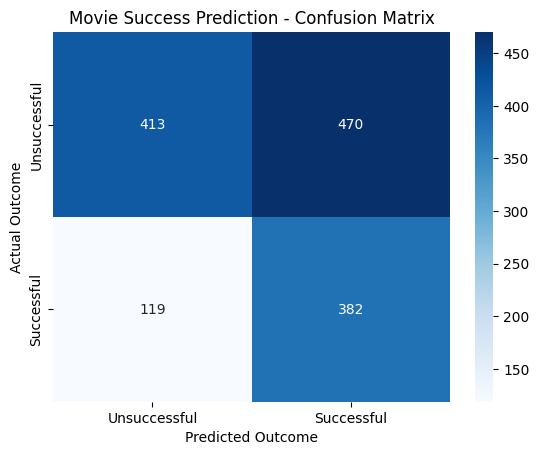

In [69]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Unsuccessful', 'Successful'],
    yticklabels=['Unsuccessful', 'Successful']
)

plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')
plt.title('Movie Success Prediction - Confusion Matrix')
plt.show()